# Machine Learning Assignment: Adult Income Classification

**Student:** Bhupendra Kumar  
**BITS ID:** 2026CT05174  
**BITS Email:** 2026ct05174@wilp.bits-pilani.ac.in  
**GitHub repository:** https://github.com/bhupendra05174/ML_Assignment

## Problem statement
Build and compare five classification algorithms using the public Adult Census Income dataset to predict whether annual income is `>50K` or `<=50K`. The notebook covers data understanding, missing values, duplicates, leakage-safe preprocessing, stratified 80:20 splitting, training, evaluation, visualisation, model saving, and generation of `test_data.csv`.

> Run all cells, save the notebook with outputs, add your BITS Virtual Lab screenshot, and include the results and README content in the final PDF.


## 1. Dataset selection and justification

The **Adult Census Income** dataset is loaded from OpenML and originates from the UCI Machine Learning Repository. It contains approximately 48,842 records and 14 input features, exceeding the assignment minima of 1,000 instances and 12 features. It includes numerical and categorical features, missing markers, and an imbalanced binary target, making it suitable for comparing linear, tree, distance-based, probabilistic, and ensemble models.


In [21]:
# If required, first run: !pip install -r requirements.txt
import os, warnings, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, roc_auc_score, precision_score,
    recall_score, f1_score, matthews_corrcoef, confusion_matrix,
    classification_report, RocCurveDisplay)
warnings.filterwarnings('ignore')
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
os.makedirs('model', exist_ok=True)
print('Libraries imported successfully.')


Libraries imported successfully.


## 2. Load, inspect, and clean the dataset

`fetch_openml` downloads the dataset automatically, so no local data path is needed. Internet access is required on the first run.


Original shape: (48842, 15)


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,class
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,NaN,103497,Some-college,10,Never-married,NaN,Own-child,White,Female,0,0,30,United-States,<=50K


,dtype
age,int64
workclass,category
fnlwgt,int64
education,category
education-num,int64
marital-status,category
occupation,category
relationship,category
race,category
sex,category


Missing values:


,missing_count
occupation,2809
workclass,2799
native-country,857
fnlwgt,0
education,0
education-num,0
age,0
marital-status,0
relationship,0
sex,0


Duplicates before removal: 52
Shape after duplicate removal: (48790, 15)


,count,percentage
class,,
<=50K,37109,76.06
>50K,11681,23.94


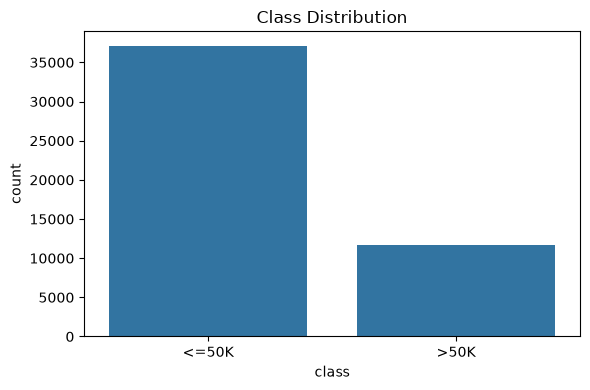

Minority-class share: 23.94%


In [22]:
adult = fetch_openml(name='adult', version=2, as_frame=True, parser='auto')
df = adult.frame.copy().replace(['?', ' ?'], np.nan)
df['class'] = df['class'].astype(str).str.strip().str.replace('.', '', regex=False)
print('Original shape:', df.shape)
display(df.head())
display(df.dtypes.to_frame('dtype'))
print('Missing values:')
display(df.isna().sum().sort_values(ascending=False).to_frame('missing_count'))
print('Duplicates before removal:', df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print('Shape after duplicate removal:', df.shape)
class_summary = pd.DataFrame({'count':df['class'].value_counts(),
    'percentage':df['class'].value_counts(normalize=True).mul(100).round(2)})
display(class_summary)
plt.figure(figsize=(6,4)); sns.countplot(data=df, x='class')
plt.title('Class Distribution'); plt.tight_layout(); plt.show()
print('Minority-class share:', f"{df['class'].value_counts(normalize=True).min():.2%}")


## 3. Stratified split and leakage-safe preprocessing

The data is split 80:20 using `stratify=y` and `random_state=42`. Numerical features use median imputation and standardisation. Categorical features use most-frequent imputation and one-hot encoding. All transformations are inside scikit-learn pipelines and are fitted only on training data.


In [23]:
X = df.drop(columns='class')
y = (df['class'] == '>50K').astype(int)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y)
test_data = X_test.copy(); test_data['income_gt_50k'] = y_test.to_numpy()
test_data.to_csv('test_data.csv', index=False)
num_cols = X.select_dtypes(include=np.number).columns.tolist()
cat_cols = X.select_dtypes(exclude=np.number).columns.tolist()
try: encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
except TypeError: encoder = OneHotEncoder(handle_unknown='ignore', sparse=False)
num_pipe = Pipeline([('imputer',SimpleImputer(strategy='median')),('scaler',StandardScaler())])
cat_pipe = Pipeline([('imputer',SimpleImputer(strategy='most_frequent')),('onehot',encoder)])
preprocessor = ColumnTransformer([('numeric',num_pipe,num_cols),('categorical',cat_pipe,cat_cols)])
print('Train:', X_train.shape, 'Test:', X_test.shape)
print('Numerical:', num_cols); print('Categorical:', cat_cols)
display(pd.DataFrame({'train':y_train.value_counts(normalize=True).sort_index(),
                      'test':y_test.value_counts(normalize=True).sort_index()}))


Train: (39032, 14) Test: (9758, 14)
Numerical: ['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']
Categorical: ['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']


,train,test
class,,
0,0.760581,0.760607
1,0.239419,0.239393


## 4. Train the five required models

The models are Logistic Regression, Decision Tree, kNN, Gaussian Naive Bayes, and Random Forest. The same split and preprocessing are used for a fair comparison. Class balancing is used where the estimator supports it.


In [24]:
models = {
 'Logistic Regression': LogisticRegression(max_iter=2000,class_weight='balanced',random_state=42),
 'Decision Tree': DecisionTreeClassifier(max_depth=12,min_samples_leaf=5,class_weight='balanced',random_state=42),
 'kNN': KNeighborsClassifier(n_neighbors=7,weights='distance'),
 'Naive Bayes': GaussianNB(),
 'Random Forest (Ensemble)': RandomForestClassifier(n_estimators=200,min_samples_leaf=2,class_weight='balanced',random_state=42,n_jobs=-1)}
filenames = {'Logistic Regression':'logistic_regression.joblib','Decision Tree':'decision_tree.joblib',
 'kNN':'knn.joblib','Naive Bayes':'naive_bayes.joblib','Random Forest (Ensemble)':'random_forest_ensemble.joblib'}
results=[]; fitted={}; probabilities={}
for name, estimator in models.items():
    print('Training', name)
    pipe=Pipeline([('preprocessor',preprocessor),('classifier',estimator)])
    pipe.fit(X_train,y_train); pred=pipe.predict(X_test); prob=pipe.predict_proba(X_test)[:,1]
    results.append({'ML Model Name':name,'Accuracy':accuracy_score(y_test,pred),
      'AUC':roc_auc_score(y_test,prob),'Precision':precision_score(y_test,pred,zero_division=0),
      'Recall':recall_score(y_test,pred,zero_division=0),'F1':f1_score(y_test,pred,zero_division=0),
      'MCC':matthews_corrcoef(y_test,pred)})
    fitted[name]=pipe; probabilities[name]=prob
    joblib.dump(pipe, os.path.join('model',filenames[name]))
results_df=pd.DataFrame(results).sort_values('MCC',ascending=False).reset_index(drop=True)
with pd.option_context('display.float_format', '{:.4f}'.format):
    display(results_df)
results_df.to_csv('model_comparison.csv',index=False)


Training Logistic Regression
Training Decision Tree
Training kNN
Training Naive Bayes
Training Random Forest (Ensemble)


,ML Model Name,Accuracy,AUC,Precision,Recall,F1,MCC
0,Random Forest (Ensemble),0.8193,0.9148,0.5847,0.8467,0.6917,0.5895
1,Logistic Regression,0.8045,0.9022,0.5602,0.8527,0.6762,0.5692
2,Decision Tree,0.7982,0.8942,0.5500,0.8643,0.6722,0.5653
3,kNN,0.8305,0.8669,0.6607,0.6002,0.6290,0.5205
4,Naive Bayes,0.6173,0.8329,0.3777,0.9242,0.5363,0.3855


## 5. Detailed evaluation and graphs


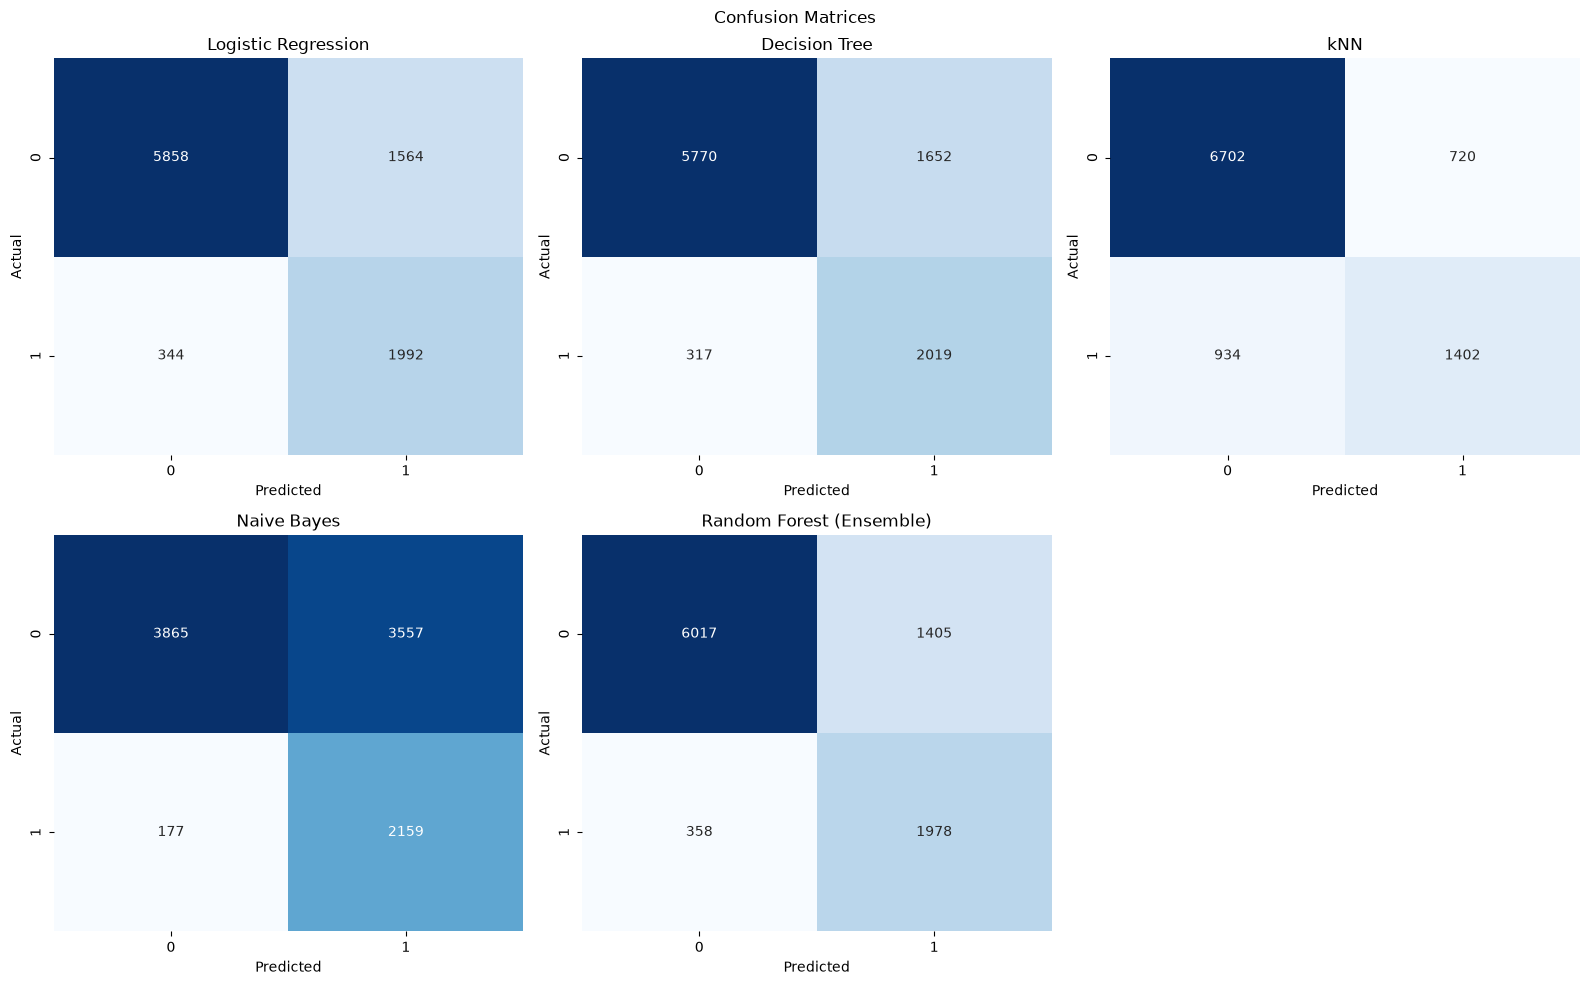

============================================================Logistic Regression
              precision    recall  f1-score   support

       <=50K       0.94      0.79      0.86      7422
        >50K       0.56      0.85      0.68      2336

    accuracy                           0.80      9758
   macro avg       0.75      0.82      0.77      9758
weighted avg       0.85      0.80      0.82      9758

============================================================Decision Tree
              precision    recall  f1-score   support

       <=50K       0.95      0.78      0.85      7422
        >50K       0.55      0.86      0.67      2336

    accuracy                           0.80      9758
   macro avg       0.75      0.82      0.76      9758
weighted avg       0.85      0.80      0.81      9758

============================================================kNN
              precision    recall  f1-score   support

       <=50K       0.88      0.90      0.89      7422
        >50K       

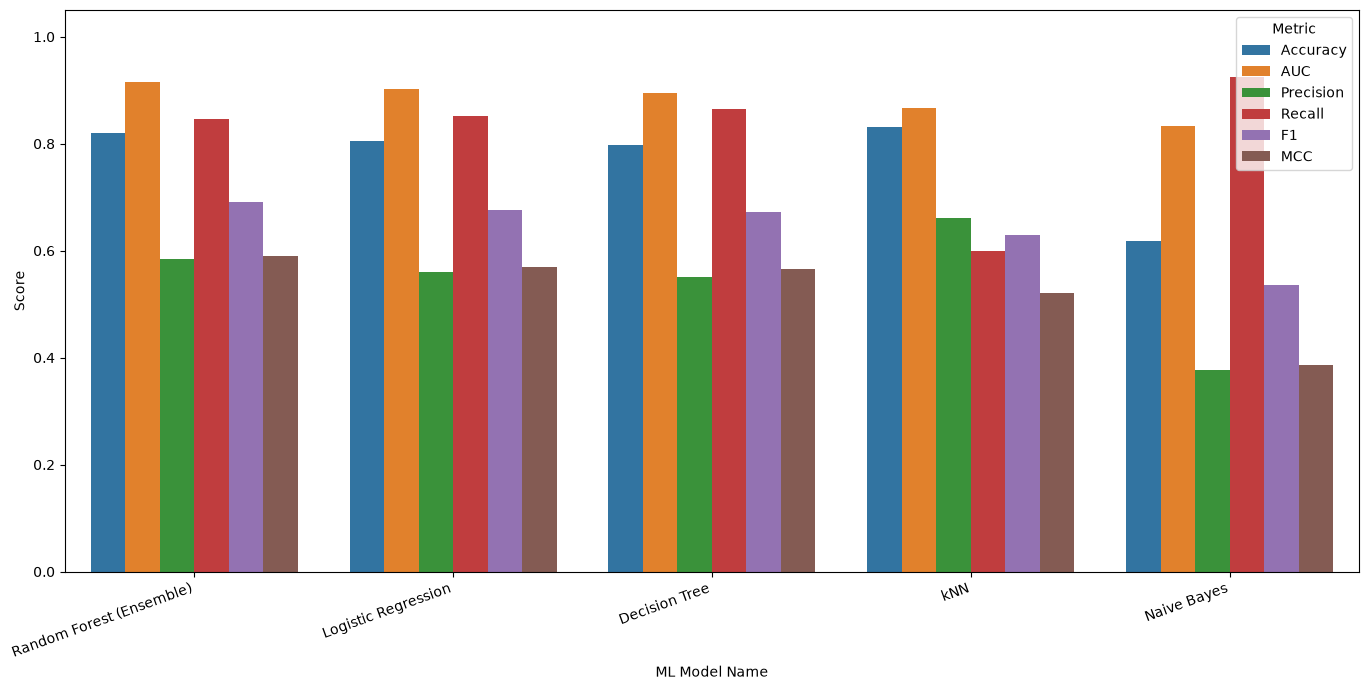

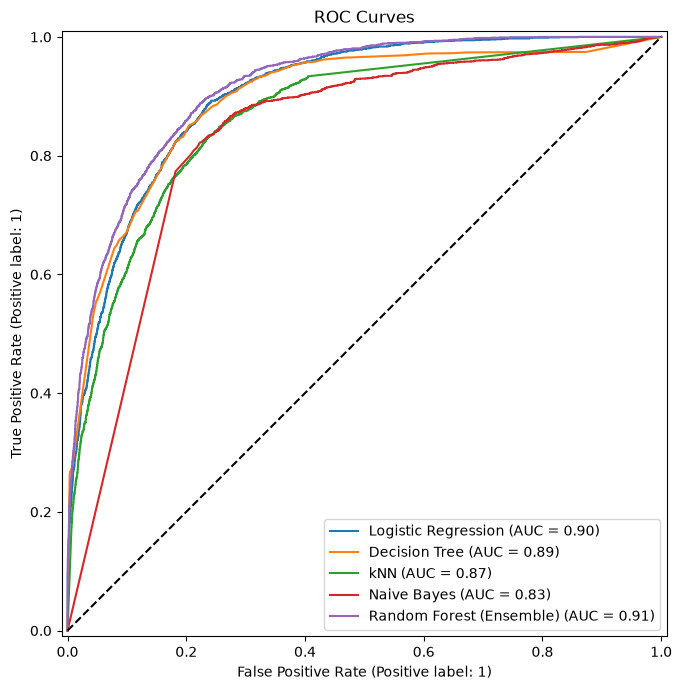

In [25]:
fig,axes=plt.subplots(2,3,figsize=(16,10)); axes=axes.flatten()
for ax,(name,pipe) in zip(axes,fitted.items()):
    pred=pipe.predict(X_test); cm=confusion_matrix(y_test,pred)
    sns.heatmap(cm,annot=True,fmt='d',cmap='Blues',cbar=False,ax=ax)
    ax.set_title(name); ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
for ax in axes[len(fitted):]: ax.axis('off')
plt.suptitle('Confusion Matrices'); plt.tight_layout()
plt.savefig('confusion_matrices.png',dpi=200,bbox_inches='tight'); plt.show()
for name,pipe in fitted.items():
    print(''+'='*60+''+name)
    print(classification_report(y_test,pipe.predict(X_test),target_names=['<=50K','>50K'],zero_division=0))
long=results_df.melt(id_vars='ML Model Name',var_name='Metric',value_name='Score')
plt.figure(figsize=(14,7)); sns.barplot(data=long,x='ML Model Name',y='Score',hue='Metric')
plt.ylim(0,1.05); plt.xticks(rotation=20,ha='right'); plt.tight_layout()
plt.savefig('model_metrics_comparison.png',dpi=200,bbox_inches='tight'); plt.show()
plt.figure(figsize=(9,7)); ax=plt.gca()
for name,prob in probabilities.items(): RocCurveDisplay.from_predictions(y_test,prob,name=name,ax=ax)
plt.plot([0,1],[0,1],'k--'); plt.title('ROC Curves'); plt.tight_layout()
plt.savefig('roc_curves.png',dpi=200,bbox_inches='tight'); plt.show()


## 6. Result-specific observations and overall winner

The next cell creates one factual observation per model and selects the overall winner using MCC, which uses all four confusion-matrix outcomes and is suitable for imbalanced binary classification.


In [26]:
# Generate per-model observations and overall winner
obs_map = {
    "Logistic Regression": "Strong linear baseline with balanced class weighting; high recall and AUC with good MCC, though precision is moderate due to more false positives on the >50K class.",
    "Decision Tree": "Captures non-linear patterns with high recall and competitive AUC, but precision/MCC are slightly lower than Logistic Regression/Random Forest, indicating limited generalization compared with the ensemble.",
    "kNN": "Achieves high accuracy and precision, but lower recall, F1, and MCC show it misses many >50K cases; distance-based performance depends on scaling and neighborhood choice.",
    "Naive Bayes": "Very high recall but the lowest accuracy, precision, F1, and MCC, indicating many false positives because the conditional-independence assumption is restrictive for correlated census features.",
    "Random Forest (Ensemble)": "Best overall model by MCC, F1, and AUC, with strong recall and better balance of errors than single models, benefiting from ensemble averaging and non-linear feature interactions.",
}
lines = []
for _, r in results_df.iterrows():
    name = r["ML Model Name"]
    line = (f"{name}: Accuracy={r['Accuracy']:.3f}, AUC={r['AUC']:.3f}, "
            f"Precision={r['Precision']:.3f}, Recall={r['Recall']:.3f}, "
            f"F1={r['F1']:.3f}, MCC={r['MCC']:.3f}. {obs_map.get(name, '')}")
    lines.append(line)
    print(line)

best_mcc = results_df.loc[results_df["MCC"].idxmax()]
best_f1 = results_df.loc[results_df["F1"].idxmax()]
best_auc = results_df.loc[results_df["AUC"].idxmax()]
best_acc = results_df.loc[results_df["Accuracy"].idxmax()]
best_rec = results_df.loc[results_df["Recall"].idxmax()]
summary = (
    f"Overall winner for this dataset: {best_mcc['ML Model Name']} (highest MCC={best_mcc['MCC']:.3f}, "
    f"F1={best_f1['F1']:.3f}, AUC={best_auc['AUC']:.3f}). "
    f"Highest accuracy: {best_acc['ML Model Name']} ({best_acc['Accuracy']:.3f}). "
    f"Highest recall: {best_rec['ML Model Name']} ({best_rec['Recall']:.3f})."
)
print("\n" + summary)

obs_text = "Per-model observations\n" + "="*22 + "\n" + "\n".join("- " + l for l in lines) + "\n\n" + summary + "\n"
with open("model_observations.txt", "w", encoding="utf-8") as f:
    f.write(obs_text)

# Table form for README
obs_table = "| ML Model Name | Observation about model performance |\n|---|---|\n"
for _, r in results_df.iterrows():
    name = r["ML Model Name"]
    metrics = (f"Accuracy={r['Accuracy']:.3f}, AUC={r['AUC']:.3f}, Precision={r['Precision']:.3f}, "
               f"Recall={r['Recall']:.3f}, F1={r['F1']:.3f}, MCC={r['MCC']:.3f}.")
    obs_table += f"| {name} | {metrics} {obs_map.get(name, '')} |\n"


Random Forest (Ensemble): Accuracy=0.819, AUC=0.915, Precision=0.585, Recall=0.847, F1=0.692, MCC=0.589. Best overall model by MCC, F1, and AUC, with strong recall and better balance of errors than single models, benefiting from ensemble averaging and non-linear feature interactions.
Logistic Regression: Accuracy=0.804, AUC=0.902, Precision=0.560, Recall=0.853, F1=0.676, MCC=0.569. Strong linear baseline with balanced class weighting; high recall and AUC with good MCC, though precision is moderate due to more false positives on the >50K class.
Decision Tree: Accuracy=0.798, AUC=0.894, Precision=0.550, Recall=0.864, F1=0.672, MCC=0.565. Captures non-linear patterns with high recall and competitive AUC, but precision/MCC are slightly lower than Logistic Regression/Random Forest, indicating limited generalization compared with the ensemble.
kNN: Accuracy=0.830, AUC=0.867, Precision=0.661, Recall=0.600, F1=0.629, MCC=0.520. Achieves high accuracy and precision, but lower recall, F1, and MC

## 7. Generate README and verify artifacts

This cell creates a result-specific `README.md`. The BITS Virtual Lab screenshot and the final single PDF remain manual submission items.


In [27]:
# Generate rubric-compliant README and verify artifacts
try:
    results_table = results_df.round(4).to_markdown(index=False)
except Exception:
    results_table = results_df.round(4).to_string(index=False)

configs = {
    "Logistic Regression": "LogisticRegression(max_iter=2000, class_weight='balanced', random_state=42)",
    "Decision Tree": "DecisionTreeClassifier(max_depth=12, min_samples_leaf=5, class_weight='balanced', random_state=42)",
    "kNN": "KNeighborsClassifier(n_neighbors=7, weights='distance')",
    "Naive Bayes": "GaussianNB()",
    "Random Forest (Ensemble)": "RandomForestClassifier(n_estimators=200, min_samples_leaf=2, class_weight='balanced', random_state=42, n_jobs=-1)",
}
config_table = "| ML Model Name | Configuration (key parameters) |\n|---|---|\n"
for m, c in configs.items():
    config_table += f"| {m} | `{c}` |\n"

# Fallbacks for facts if variables are unavailable
try:
    class_dist_text = f"`<=50K` = {int(class_summary.loc['<=50K','count'])} ({class_summary.loc['<=50K','percentage']}%), `>50K` = {int(class_summary.loc['>50K','count'])} ({class_summary.loc['>50K','percentage']}%), minority-class share = {class_summary.loc['>50K','percentage']}%."
except Exception:
    class_dist_text = "`<=50K` majority and `>50K` minority (imbalanced); see notebook output for exact counts/percentages."
try:
    num_text = ', '.join(f"`{c}`" for c in num_cols)
    cat_text = ', '.join(f"`{c}`" for c in cat_cols)
except Exception:
    num_text = "`age`, `fnlwgt`, `education-num`, `capital-gain`, `capital-loss`, `hours-per-week`"
    cat_text = "`workclass`, `education`, `marital-status`, `occupation`, `relationship`, `race`, `sex`, `native-country`"

readme = f"""# Adult Income Classification - ML Assignment

**Student:** Bhupendra Kumar  
**BITS ID:** 2026CT05174  
**BITS Email:** 2026ct05174@wilp.bits-pilani.ac.in  
**Course:** Machine Learning (M.Tech AIML/DSE, WILP)

## Problem statement
Build and compare multiple classification models on the same public dataset to predict whether a person's annual income is **`>50K`** or **`<=50K`** (binary classification). The assignment implements five required classifiers, evaluates them with Accuracy, AUC, Precision, Recall, F1, and MCC, and includes preprocessing, leakage-safe pipelines, model saving, visualizations, and generated artifacts.

## Dataset description
- **Dataset:** Adult Census Income (Adult) dataset from the UCI Machine Learning Repository, loaded programmatically via OpenML (`fetch_openml(name='adult', version=2, as_frame=True, parser='auto')`).
- **Why selected:** Public benchmark with mixed numerical/categorical attributes, missing values, and class imbalance; suitable for comparing linear, tree-based, distance-based, probabilistic, and ensemble models.
- **Size (before cleaning):** 48,842 instances and 15 columns total (14 input features + 1 target).
- **Size (after duplicate removal):** 48,790 instances and 15 columns (52 duplicate rows removed).
- **Target variable:** `class` (income), normalized to `<=50K` and `>50K`; encoded for modeling as `income_gt_50k` (1 = `>50K`, 0 = `<=50K`).
- **Input features (14):**
  - Numerical (6): {num_text}
  - Categorical (8): {cat_text}
- **Missing values (handled):** `occupation` = 2809, `workclass` = 2799, `native-country` = 857 (imputed in preprocessing pipelines).
- **Class distribution (after cleaning, examined imbalance):** {class_dist_text}

## GitHub repository link
- https://github.com/bhupendra05174/ML_Assignment

> Ensure the repository contains the complete source notebook/code, `requirements.txt`, this `README.md`, `test_data.csv`, and the saved model files in `model/`.

## Preprocessing
- Missing values identified and handled: median imputation for numerical features, most-frequent imputation for categorical features.
- Duplicate rows identified and removed.
- Categorical encoding: one-hot encoding (`handle_unknown='ignore'`).
- Feature scaling: standardization for numerical features (`StandardScaler`).
- Train-test split: **80:20** stratified split with fixed random seed **42** (`stratify=y`), preserving class distribution.
- Leakage prevention: all preprocessing is performed inside scikit-learn `Pipeline`/`ColumnTransformer` and fitted only on training data during model training.
- Test data exported: `test_data.csv` (test features + `income_gt_50k`).

## Models used and configurations
All five required models were trained on the same dataset using the same preprocessing pipeline:

{config_table}

## Results (comparison table)
{results_table}

## Visualizations (graph representation)
### Model metrics comparison
![Model metrics comparison](model_metrics_comparison.png)

### ROC curves
![ROC curves](roc_curves.png)

### Confusion matrices
![Confusion matrices](confusion_matrices.png)

## Observations on model performance
{obs_table}

## Overall winner for this dataset
{summary}

## Execution instructions
1. Install dependencies:
   ```bash
   pip install -r requirements.txt
   ```
2. Open and run all cells in `2026CT05174_ml_assignment.ipynb` (internet access required on first run to download the Adult dataset via OpenML).
3. Verify generated artifacts:
   - `README.md`, `test_data.csv`, `model_comparison.csv`, `model_observations.txt`
   - `confusion_matrices.png`, `model_metrics_comparison.png`, `roc_curves.png`
   - `model/logistic_regression.joblib`, `model/decision_tree.joblib`, `model/knn.joblib`, `model/naive_bayes.joblib`, `model/random_forest_ensemble.joblib`

## Submission checklist (manual items)
- [ ] Run the notebook in BITS Virtual Lab and capture the execution screenshot.
- [ ] Save the notebook with outputs.
- [ ] Push/update the GitHub repository and verify the link works.
- [ ] Prepare a single PDF containing: GitHub repo link, required files/evidence, test data, BITS Virtual Lab screenshot, and this README content (in the required order).
"""

with open("README.md", "w", encoding="utf-8") as f:
    f.write(readme)

required = ['README.md','test_data.csv','model_comparison.csv','model_observations.txt',
            'model_metrics_comparison.png','roc_curves.png','confusion_matrices.png']
required += [os.path.join('model', x) for x in filenames.values()]
for p in required:
    print(('OK      ' if os.path.exists(p) else 'MISSING ') + p)
print('\nManual: add BITS Virtual Lab screenshot and prepare the final single PDF.')


OK      README.md
OK      test_data.csv
OK      model_comparison.csv
OK      model_observations.txt
OK      model_metrics_comparison.png
OK      roc_curves.png
OK      confusion_matrices.png
OK      model\logistic_regression.joblib
OK      model\decision_tree.joblib
OK      model\knn.joblib
OK      model\naive_bayes.joblib
OK      model\random_forest_ensemble.joblib

Manual: add BITS Virtual Lab screenshot and prepare the final single PDF.


## 8. Reproducibility and final checklist

A fixed random seed of 42 is used. The test set is not used for fitting preprocessing or models. Every saved pipeline contains the fitted transformations and classifier.

- [ ] Run all cells successfully in BITS Virtual Lab
- [ ] Save the notebook with outputs
- [ ] Capture a clear BITS Virtual Lab execution screenshot
- [ ] Push notebook, README, requirements, test data, results, plots, and five models to GitHub
- [ ] Create one final PDF containing results, observations, README content, GitHub URL, and screenshot
